In [ ]:
import torch
import numpy as np
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
from typing import NamedTuple
from collections import deque
import gymnasium as gym
from abc import abstractmethod
import random
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# %%writefile CRNetwork.py
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import torch


device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


class CRNetwork(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self, n_ST=2, noise=1e-6, int_thresh=-28.0,
        max_power=10e-3, steps_per_run=100, dtype=np.float32, seed=None,
        interference_reference_w=1.0, error_variance=0.1, hist_len = 1,
        reward_mode="paper", alpha=0.2,beta=10.0):
        super().__init__()

        if not isinstance(n_ST, (int, np.integer)) or n_ST < 1:
            raise ValueError("n_ST must be a positive integer.")
        if not isinstance(steps_per_run, (int, np.integer)) or steps_per_run < 1:
            raise ValueError("steps_per_run must be a positive integer.")
        if not np.issubdtype(np.dtype(dtype), np.floating):
            raise ValueError("Use a floating-point observation dtype.")

        parameters = (noise, int_thresh, max_power, interference_reference_w)
        if not np.all(np.isfinite(parameters)):
            raise ValueError("Environment parameters must be finite.")
        if noise <= 0 or max_power <= 0 or interference_reference_w <= 0:
            raise ValueError("Noise, power budget, and interference reference must be positive.")
        if not np.isfinite(error_variance) or error_variance < 0:
            raise ValueError("error_variance must be finite and nonnegative.")
        if not np.isfinite(alpha) or not 0 <= alpha <= 1:
            raise ValueError("alpha must be between 0 and 1.")
        if not np.isfinite(beta) or beta < 0:
            raise ValueError("beta must be finite and nonnegative.")

        self.k = int(n_ST)
        self.N0 = float(noise)
        self.Pmax = float(max_power)
        self.Ith = float(10**(int_thresh / 10))

        if not np.isfinite(self.Ith) or self.Ith <= 0:
            raise ValueError("Converted interference threshold must be finite and positive.")

        self.max_steps = int(steps_per_run)
        self.dtype = np.dtype(dtype)

        self.hist_len = int(hist_len)
        assert self.hist_len >= 1
        self.obs_dim = (self.hist_len + 1) * self.k + 1
        self.action_dim = self.k

        self.error_variance = float(error_variance)
        self.beta = float(beta)
        self.alpha = float(alpha)

        self.reward_mode = "paper" if reward_mode == "paper" else "custom"

        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(self.obs_dim,),
            dtype=self.dtype
        )
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(self.k,),
            dtype=self.dtype
        )

        # Random number generator
        self.np_random = np.random.default_rng(seed)
        self.step_count = 0
        self._needs_reset = True

    def get_channel_gain(self, update=True):

        # Update complex channel coefficients only when requested
        if update:
           # Noisy estimate
            w_p = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)
            w_s = (self.np_random.standard_normal(self.k)+ 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

            # Temporally correlated ST-PR channels
            self.hint = ((1 - self.alpha) * self.hint + np.sqrt(2 * self.alpha - self.alpha**2) * w_p)
            self.hsr = ((1 - self.alpha) * self.hsr + np.sqrt(2 * self.alpha - self.alpha**2) * w_s)
        # Actual channel power gains
        g_pr_actual = np.abs(self.hint)**2
        g_sr = np.abs(self.hsr)**2
        # Imperfect CSI on ST-PR links only
        error = np.sqrt(self.error_variance / 2) * (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k))

        hpr_est = self.hint + error
        gpr_est = np.abs(hpr_est)**2
        self.hpr_est = hpr_est

        return g_pr_actual, gpr_est, g_sr

    def _observation(self):
        # return np.concatenate(
        #     [self.hint_est, self.P_prev, [self.r_prev]]
        # ).astype(self.dtype)
        return np.concatenate([self.est_hist.ravel(), self.P_prev, [self.r_prev]]).astype(self.dtype)

    def reset(self, *, seed=None, options=None):

        super().reset(seed=seed)

        self.step_count = 0
        self.P_prev = np.zeros(self.k)
        self.r_prev = 0.0

        # Initialize complex channel coefficients
        self.hint = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        self.hsr = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        # Initial channel gains and imperfect CSI
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=False))
        self.est_hist = np.tile(self.hint_est, (self.hist_len, 1))   # pad history with the current estimate

        self._needs_reset = False

        return self._observation(), {}

    def step(self, action):

        if self._needs_reset:
            raise RuntimeError("Call reset() before stepping or after an episode ends.")

        action = np.asarray(action, dtype=np.float64)

        if action.shape != (self.k,) or not np.all(np.isfinite(action)):
            raise ValueError(f"Expected a finite action with shape ({self.k},).")

        raw_action = np.clip(action, -1.0, 1.0)

        # Action-to-power mapping
        fractions = (raw_action + 1.0) / 2.0
        powers = fractions * self.Pmax

        # Capacity using actual desired channel gains
        signal_power = powers * self.g_sr
        snr = signal_power / self.N0
        capacity = np.log2(1.0 + snr)

        # Actual primary interference
        interference = float(np.sum(powers * self.g_pr_actual))

        normalized_violation = max(
            0.0,
            (interference - self.Ith) / self.Ith
        )

        power_ok = bool(
            np.all(powers >= 0) and np.all(powers <= self.Pmax)
        )

        feasible = bool(interference <= self.Ith and power_ok)

        # Reward calculation
        if self.reward_mode == "paper":
            reward = float(capacity.sum()) if feasible else -interference
        else:
            reward = float(capacity.sum()) - self.beta * normalized_violation

        info = {
            "capacity": capacity.copy(),
            "snr": snr.copy(),
            "interference": interference,
            "constraints_satisfied": feasible,
            "allocation_fractions": fractions.copy(),
            "transmit_powers": powers.copy(),
            "actual_interference_gains": self.g_pr_actual.copy(),
            "desired_gains": self.g_sr.copy(),
            "estimated_interference": float(np.sum(powers * self.hint_est)),
            "normalized_excess": float(normalized_violation),
            "penalty": float(self.beta * normalized_violation),
            "actual_violation": bool(interference > self.Ith),
            "estimated_violation": bool(np.sum(powers * self.hint_est) > self.Ith),
        }
        # Store previous action and reward
        self.P_prev = powers.copy()
        self.r_prev = reward

        self.step_count += 1

        terminated = False
        truncated = bool(self.step_count >= self.max_steps)

        # Generate next channel realization for the next observation
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=True))
        self.est_hist = np.vstack([self.hint_est, self.est_hist[:-1]])  # newest first

        self._needs_reset = truncated

        return self._observation(), reward, terminated, truncated, info


In [ ]:


"""RolloutBuffer class for PPO and A2C"""
class RolloutBuffer:

    def __init__(self):
        self.actions = []       # Pre-tanh Gaussian samples
        self.states = []
        self.logprobs = []
        self.rewards = []
        self.costs = []
        self.state_values = []
        self.is_terminals = []

    def clear(self):
        self.actions.clear()
        self.states.clear()
        self.logprobs.clear()
        self.rewards.clear()
        self.costs.clear()
        self.state_values.clear()
        self.is_terminals.clear()

In [ ]:
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal
import torch.nn.functional as F


class A2C:

    def __init__(self, state_dim, action_dim,
        actor_lr=1e-3, critic_lr=2e-3, gamma=0.99,
        action_std=0.2, entropy_coef=0.01,
        min_log_std=np.log(0.05), max_log_std=np.log(0.5),
        gae_lambda=0.95, device=None, buffer=None, normalize_advantages=True
    ):

        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))

        self.gamma = float(gamma)
        self.gae_lambda = float(gae_lambda)
        self.entropy_coef = float(entropy_coef)
        self.normalize_advantages = bool(normalize_advantages)

        self.min_log_std = float(min_log_std)
        self.max_log_std = float(max_log_std)

        if action_std <= 0 or not np.isfinite(action_std):
            raise ValueError("action_std must be positive.")
        if self.entropy_coef < 0:
            raise ValueError("entropy_coef cannot be negative.")
        if not 0.0 <= self.gae_lambda <= 1.0:
            raise ValueError("gae_lambda must be between 0 and 1.")
        if not 0.0 <= self.gamma <= 1.0:
            raise ValueError("gamma must be between 0 and 1.")

        self.buffer = RolloutBuffer() if buffer is None else buffer
        self.next_values = []

        # Actor Network
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        ).to(self.device)

        with torch.no_grad():
            final_layer = self.actor[-1]
            final_layer.weight.mul_(0.1)
            final_layer.bias.fill_(-0.693)

        self.log_std = nn.Parameter(
            torch.full(
                (action_dim,),
                np.log(action_std),
                dtype=torch.float32,
                device=self.device
            )
        )

        # Critic Network
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        ).to(self.device)

        self.actor_optimizer = torch.optim.Adam(
            list(self.actor.parameters()) + [self.log_std],
            lr=actor_lr
        )

        self.critic_optimizer = torch.optim.Adam(
            self.critic.parameters(),
            lr=critic_lr
        )

        self.last_update_stats = {}

    def tensor(self, data):
        return torch.as_tensor(
            np.asarray(data),
            dtype=torch.float32,
            device=self.device
        )

    def get_distribution(self, states):

        mean = self.actor(states)

        log_std = torch.clamp(
            self.log_std,
            min=self.min_log_std,
            max=self.max_log_std
        )

        std = torch.exp(log_std)

        return Normal(mean, std)

    @staticmethod
    def tanh_log_det(z):
        # Numerically stable log(1 - tanh(z)^2)
        return 2.0 * (
            np.log(2.0) - z - F.softplus(-2.0 * z)
        )

    @torch.no_grad()
    def choose_action(self, state, deterministic=False):

        state_tensor = self.tensor(state)

        distribution = self.get_distribution(state_tensor)

        if deterministic:
            z = distribution.mean
        else:
            z = distribution.sample()

        action = torch.tanh(z)

        # Log probability of transformed action
        logprob = (
            distribution.log_prob(z)
            - self.tanh_log_det(z)
        ).sum(dim=-1)

        return (
            action.cpu().numpy(),
            z.cpu().numpy(),
            logprob.item()
        )

    @torch.no_grad()
    def remember(
        self,
        state,
        raw_action,
        logprob,
        reward,
        next_state,
        terminated,
        truncated
    ):

        self.buffer.states.append(
            np.array(state, dtype=np.float32, copy=True)
        )

        # Store pre-tanh Gaussian sample
        self.buffer.actions.append(
            np.array(raw_action, dtype=np.float32, copy=True)
        )

        self.buffer.logprobs.append(float(logprob))
        self.buffer.rewards.append(float(reward))

        value = self.critic(
            self.tensor(state)
        ).item()

        self.buffer.state_values.append(value)

        # Bootstrap unless the environment truly terminates.
        # Time-limit truncation still uses next-state value.
        if terminated:
            next_value = 0.0
        else:
            next_value = self.critic(
                self.tensor(next_state)
            ).item()

        self.next_values.append(next_value)

        # Stop GAE recursion at either episode boundary.
        self.buffer.is_terminals.append(
            bool(terminated or truncated)
        )

    def update(self):

        batch_size = len(self.buffer.rewards)

        if batch_size == 0:
            return None

        states = self.tensor(self.buffer.states)
        raw_actions = self.tensor(self.buffer.actions)
        rewards = self.tensor(self.buffer.rewards)
        old_values = self.tensor(self.buffer.state_values)
        next_values = self.tensor(self.next_values)



        with torch.no_grad():

            advantages = torch.zeros_like(rewards)
            gae = 0.0

            for t in reversed(range(batch_size)):

                # Temporal difference error
                delta = (
                    rewards[t]
                    + self.gamma * next_values[t]
                    - old_values[t]
                )

                # Do not propagate GAE across episode boundaries
                continuation_mask = (
                    0.0 if self.buffer.is_terminals[t] else 1.0
                )

                # GAE calculation
                gae = (
                    delta
                    + self.gamma
                    * self.gae_lambda
                    * continuation_mask
                    * gae
                )

                advantages[t] = gae

            # Critic target
            returns = advantages + old_values

        raw_advantage_mean = advantages.mean().item()
        raw_advantage_std = advantages.std(unbiased=False).item()

        # Optional advantage normalization
        if self.normalize_advantages and batch_size > 1:

            advantages = (
                advantages - advantages.mean()
            ) / (
                advantages.std(unbiased=False) + 1e-8
            )


        distribution = self.get_distribution(states)

        # Log probability with tanh correction
        log_det = self.tanh_log_det(raw_actions)

        logprobs = (
            distribution.log_prob(raw_actions) - log_det
        ).sum(dim=-1)

        policy_loss = -(
            logprobs * advantages.detach()
        ).mean()


        entropy = distribution.entropy().sum(dim=-1).mean()

        actor_loss = (
            policy_loss - self.entropy_coef * entropy
        )

        self.actor_optimizer.zero_grad()
        actor_loss.backward()

        actor_grad_norm = nn.utils.clip_grad_norm_(
            list(self.actor.parameters()) + [self.log_std],
            max_norm=0.5
        )

        self.actor_optimizer.step()

        # Keep standard deviation within configured limits
        with torch.no_grad():
            self.log_std.clamp_(
                min=self.min_log_std,
                max=self.max_log_std
            )



        predictions = self.critic(states).squeeze(-1)

        critic_loss = (
            predictions - returns.detach()
        ).pow(2).mean()

        self.critic_optimizer.zero_grad()
        critic_loss.backward()

        critic_grad_norm = nn.utils.clip_grad_norm_(
            self.critic.parameters(),
            max_norm=0.5
        )

        self.critic_optimizer.step()


        with torch.no_grad():

            current_std = torch.exp(
                torch.clamp(
                    self.log_std,
                    self.min_log_std,
                    self.max_log_std
                )
            )

            self.last_update_stats = {
                "actor_loss": actor_loss.item(),
                "policy_loss": policy_loss.item(),
                "critic_loss": critic_loss.item(),
                "entropy": entropy.item(),

                "mean_advantage": raw_advantage_mean,
                "std_advantage": raw_advantage_std,

                "mean_return": returns.mean().item(),
                "std_return": returns.std(
                    unbiased=False
                ).item(),

                "mean_value": predictions.mean().item(),

                "actor_grad_norm": float(actor_grad_norm),
                "critic_grad_norm": float(critic_grad_norm),

                "std_su1": current_std[0].item(),
                "std_su2": current_std[1].item(),

                "gae_lambda": self.gae_lambda
            }

        # Clear rollout data
        self.buffer.clear()
        self.next_values.clear()

        return [
            actor_loss.item(),
            critic_loss.item()
        ]

    def save(self, path):

        Path(path).parent.mkdir(
            parents=True,
            exist_ok=True
        )

        torch.save(
            {
                "actor": self.actor.state_dict(),
                "critic": self.critic.state_dict(),
                "log_std": self.log_std.detach().cpu(),

                "entropy_coef": self.entropy_coef,
                "min_log_std": self.min_log_std,
                "max_log_std": self.max_log_std,

                "gamma": self.gamma,
                "gae_lambda": self.gae_lambda
            },
            path
        )

    def load(self, path):

        if self.buffer.states:
            raise RuntimeError(
                "Finish the current rollout before loading."
            )

        checkpoint = torch.load(
            path,
            map_location=self.device,
            weights_only=True
        )

        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])

        self.entropy_coef = checkpoint.get(
            "entropy_coef",
            self.entropy_coef
        )

        self.gamma = checkpoint.get(
            "gamma",
            self.gamma
        )

        self.gae_lambda = checkpoint.get(
            "gae_lambda",
            self.gae_lambda
        )

        self.min_log_std = checkpoint.get(
            "min_log_std",
            self.min_log_std
        )

        self.max_log_std = checkpoint.get(
            "max_log_std",
            self.max_log_std
        )

        if "log_std" in checkpoint:

            with torch.no_grad():
                self.log_std.copy_(
                    checkpoint["log_std"].to(self.device)
                )

        elif "action_std" in checkpoint:

            with torch.no_grad():
                self.log_std.fill_(
                    np.log(checkpoint["action_std"])
                )

        print(f"A2C checkpoint loaded: {path}")


# Settings and Configurations

In [ ]:
from google.colab import files
files.upload();


Saving utils.py to utils.py


In [ ]:
from pathlib import Path
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from utils import *

#=============================================================
#               CONFIGURATIONS
#=============================================================

N_ST = 2

MAX_POWER_MW = 10.0
NOISE_POWER_MW = 1e-3
ITH_DBM = 2.0

MAX_POWER = MAX_POWER_MW * 1e-3
N0 = NOISE_POWER_MW * 1e-3

ITH_DBW = ITH_DBM - 30.0

STEPS_PER_RUN = 100
NUM_EPISODES = 1000
TOTAL_TRAINING_STEPS = NUM_EPISODES * STEPS_PER_RUN

ACTOR_LR = 1e-3
CRITIC_LR = 1e-3

GAMMA = 0.99

ACTION_STD = 0.2
ENTROPY_COEF = 0.01

MIN_ACTION_STD = 0.05
START_MAX_ACTION_STD = 0.25
END_MAX_ACTION_STD = 0.10

ROLLOUT_STEPS = 128

EVAL_EPISODES = 1000
EVAL_SEED_OFFSET = 100_000

SMOOTH_WINDOW = 500

seed = 0

OUTPUT_DIR = Path("a2c_5d")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



torch.manual_seed(seed)
np.random.seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


env = CRNetwork(
    n_ST=N_ST,
    noise=N0,
    int_thresh=ITH_DBW,
    max_power=MAX_POWER,
    steps_per_run=STEPS_PER_RUN,
    dtype=np.float32,
    seed=seed,
    alpha=1.0,
    error_variance = 0.0
)




expected_ith_w = dbm_to_watts(ITH_DBM)

assert np.isclose(env.Ith, expected_ith_w, rtol=1e-6)
assert np.isclose(env.N0, N0)
assert np.isclose(env.Pmax, MAX_POWER)

STATE_DIM = env.observation_space.shape[0]
ACTION_DIM = env.action_space.shape[0]

assert STATE_DIM == 5, f"Expected 5 states, got {STATE_DIM}"
assert ACTION_DIM == 2, f"Expected 2 actions, got {ACTION_DIM}"

assert ROLLOUT_STEPS > 0
assert STEPS_PER_RUN > 0

print("\n========== ENVIRONMENT CONFIGURATION ==========")
print(f"Secondary pairs       : {N_ST}")
print(f"State dimension       : {STATE_DIM}")
print(f"Action dimension      : {ACTION_DIM}")
print(f"Maximum power         : {MAX_POWER_MW:.2f} mW per SU")
print(f"Noise power           : {N0:.6e} W")
print(f"Interference threshold: {ITH_DBM:.2f} dBm")
print(f"Training steps        : {TOTAL_TRAINING_STEPS}")
print(f"Rollout length        : {ROLLOUT_STEPS}")
print(f"CSI error variance    : {env.error_variance}")
print("===============================================\n")



a2c_agent = A2C(
    state_dim=STATE_DIM,
    action_dim=ACTION_DIM,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    gamma=GAMMA,
    action_std=ACTION_STD,
    entropy_coef=ENTROPY_COEF,
    normalize_advantages=True,
    device=None
)

training_device = next(
    a2c_agent.actor.parameters()
).device

print("Training device:", training_device)




========== ENVIRONMENT CONFIGURATION ==========
Secondary pairs       : 2
State dimension       : 5
Action dimension      : 2
Maximum power         : 10.00 mW per SU
Noise power           : 1.000000e-06 W
Interference threshold: 2.00 dBm
Training steps        : 100000
Rollout length        : 128
CSI error variance    : 0.0

Training device: cpu


# Training and Evaluation

Episode    1/1000 | Steps    100 | Reward   3.9457 | Capacity  20.5925 | Interference    6.763 dBm | Violations  81.00% | Std [0.1001, 0.1002] 
Episode   11/1000 | Steps   1100 | Reward   2.6494 | Capacity  20.1762 | Interference    6.906 dBm | Violations  86.00% | Std [0.0999, 0.0983] 
Episode   21/1000 | Steps   2100 | Reward   2.5685 | Capacity  21.1185 | Interference    8.355 dBm | Violations  88.00% | Std [0.0994, 0.0981] 
Episode   31/1000 | Steps   3100 | Reward   2.8380 | Capacity  20.6498 | Interference    8.092 dBm | Violations  86.00% | Std [0.0985, 0.0976] 
Episode   41/1000 | Steps   4100 | Reward   2.8992 | Capacity  20.0101 | Interference    7.403 dBm | Violations  85.00% | Std [0.0982, 0.0971] 
Episode   51/1000 | Steps   5100 | Reward   2.4644 | Capacity  18.5022 | Interference    9.461 dBm | Violations  87.00% | Std [0.0977, 0.0967] 
Episode   61/1000 | Steps   6100 | Reward   2.9856 | Capacity  17.4329 | Interference    8.926 dBm | Violations  83.00% | Std [0.0975, 0

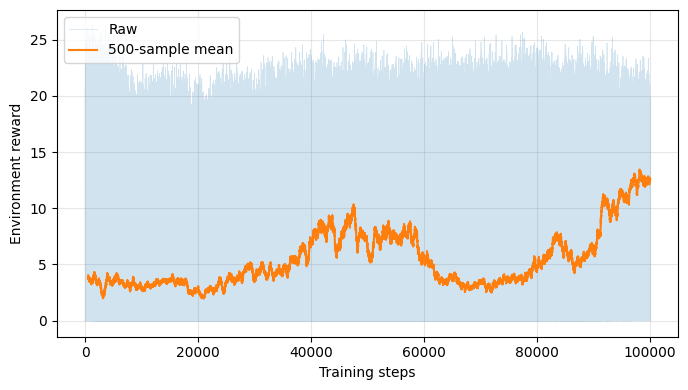

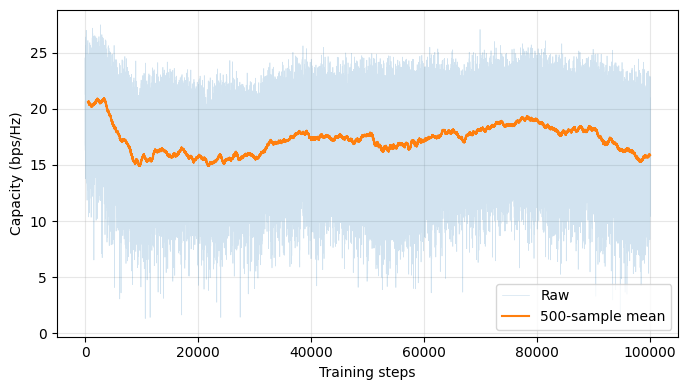

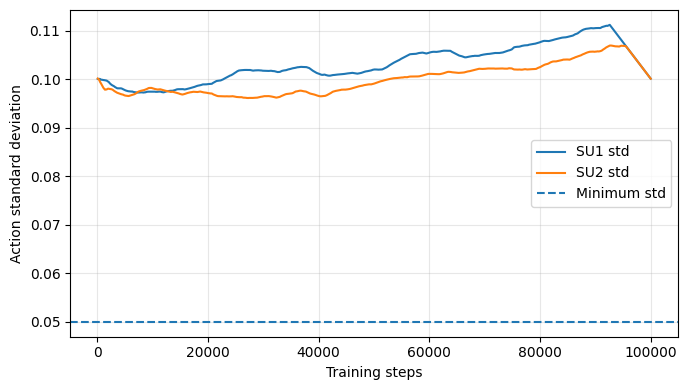

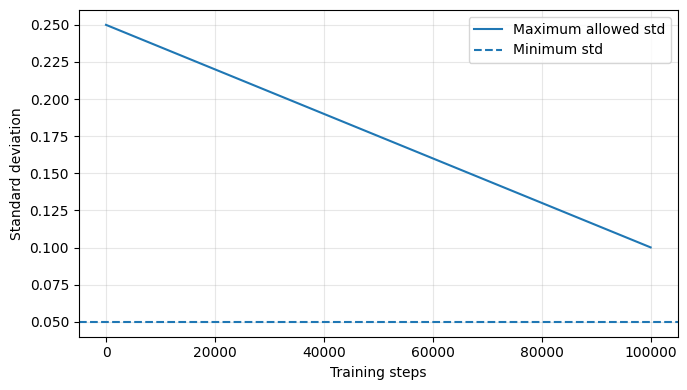

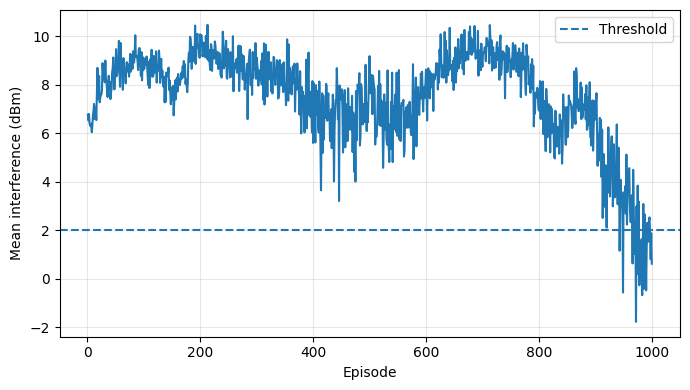

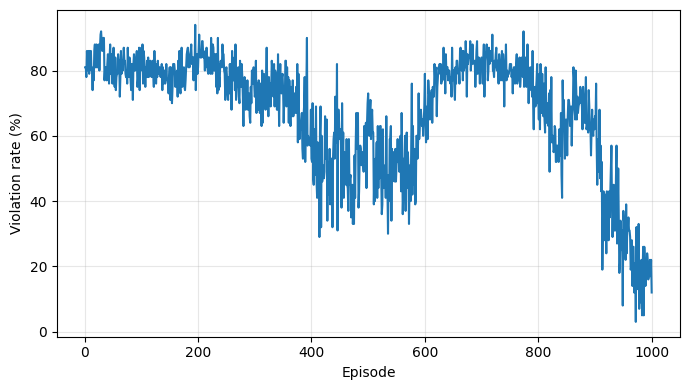

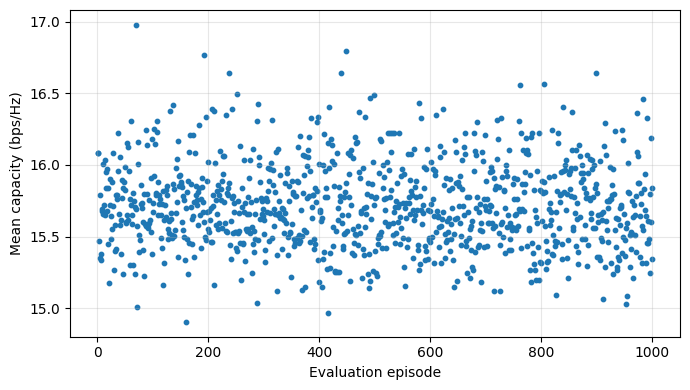

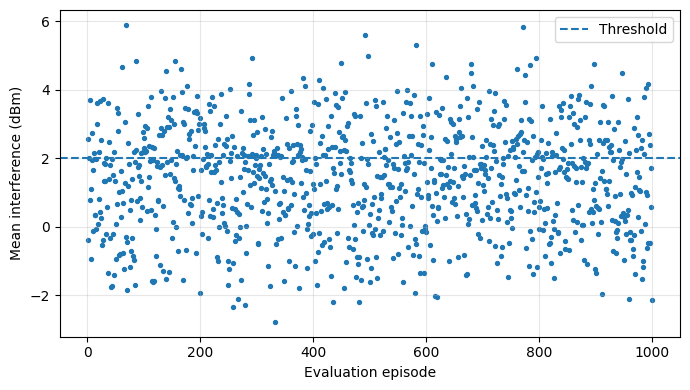

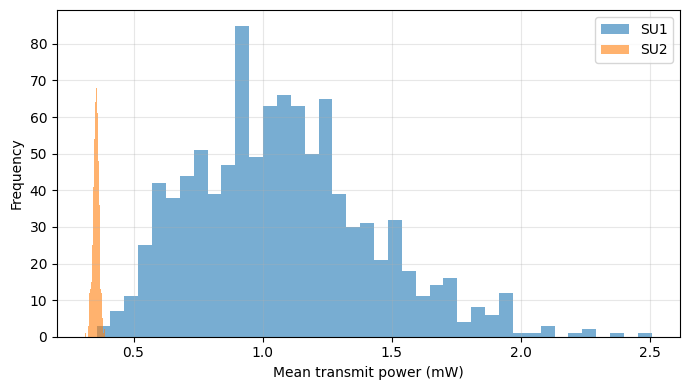

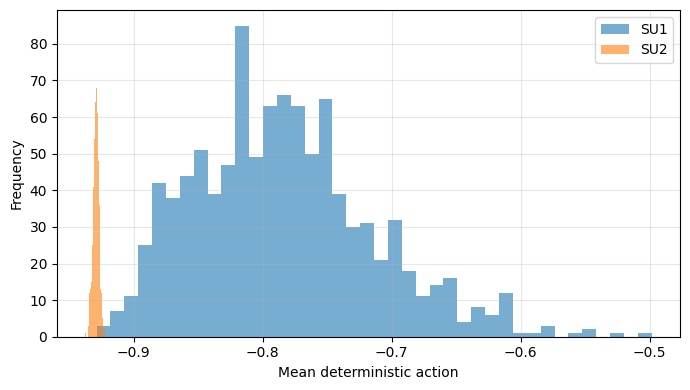


                  A2C RESULTS

Training steps: 100000
Training time: 67.56 seconds

TRAINING
Mean reward: 5.4393
Mean capacity: 17.2278 bps/Hz
Mean interference: 7.8802 dBm
Violation rate: 67.28%
Constraint satisfaction: 32.72%
Mean total power: 5.9572 mW

EVALUATION
Mean reward: 12.8388
Mean capacity: 15.7184 +/- 0.2965 bps/Hz
Mean interference: 1.6659 dBm
Threshold: 2.00 dBm
Violation rate: 16.17%
Constraint satisfaction: 83.83%
SU1 mean power: 1.0782 mW
SU2 mean power: 0.3547 mW
SU1 mean action: -0.7844
SU2 mean action: -0.9291

Final SU1 std: 0.1002
Final SU2 std: 0.1001
Execution time: 0.2468 ms/action

Saved results to:
/content/a2c_5d


In [ ]:
step_numbers = []
step_rewards = []
step_capacities = []

step_powers = []
step_total_power = []

step_violations = []
step_actions = []

step_interference_w = []

episode_interference_w = []
episode_interference_dbm = []
episode_violation_rate = []
episode_reward = []
episode_capacity = []

actor_losses = []
critic_losses = []
policy_losses = []
entropy_history = []

std_su1_history = []
std_su2_history = []

max_std_history = []
schedule_steps = []
loss_steps = []

total_time = 0


# ============================================================
# 12. TRAINING LOOP
# ============================================================

if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

start_time = time.perf_counter()

for episode in range(NUM_EPISODES):

    obs, _ = env.reset(seed=seed + episode)

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    )

    ep_interference_sum = 0.0
    ep_violations = 0
    ep_reward_sum = 0.0
    ep_capacity_sum = 0.0

    for j in range(STEPS_PER_RUN):

        # --------------------------------------------
        # ACTION STD SCHEDULE
        # --------------------------------------------

        if len(a2c_agent.buffer.rewards) == 0:

            progress = total_time / TOTAL_TRAINING_STEPS

            current_max_std, actual_std = (
                update_action_std_schedule(
                    a2c_agent,
                    progress
                )
            )

            max_std_history.append(current_max_std)
            schedule_steps.append(total_time)

        # --------------------------------------------
        # SELECT ACTION
        # --------------------------------------------

        action, raw_action, logprob = a2c_agent.choose_action(
            obs,
            deterministic=False
        )

        action = np.asarray(
            action,
            dtype=np.float32
        )

        # --------------------------------------------
        # ENVIRONMENT STEP
        # --------------------------------------------

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        )

        reward = float(reward)

        capacity = np.asarray(
            info["capacity"],
            dtype=np.float64
        )

        powers_w = step_powers_w(
            info,
            action,
            env
        )

        interference_w = float(info["interference"])

        # --------------------------------------------
        # DIRECT INTERFERENCE VIOLATION CHECK
        # --------------------------------------------

        training_reward = reward

        violated = is_interference_violated(
            interference_w,
            env.Ith
        )

        # --------------------------------------------
        # RECORD STEP STATISTICS
        # --------------------------------------------

        total_time += 1

        step_numbers.append(total_time)
        step_rewards.append(reward)
        step_capacities.append(float(capacity.sum()))

        step_powers.append(powers_w.copy())
        step_total_power.append(float(powers_w.sum()))

        step_violations.append(int(violated))
        step_actions.append(action.copy())

        step_interference_w.append(interference_w)

        # --------------------------------------------
        # EPISODE STATISTICS
        # --------------------------------------------

        ep_interference_sum += interference_w
        ep_violations += int(violated)
        ep_reward_sum += reward
        ep_capacity_sum += float(capacity.sum())

        # --------------------------------------------
        # STORE TRANSITION IN A2C
        # --------------------------------------------

        a2c_agent.remember(
            obs,
            raw_action,
            logprob,
            training_reward,
            next_obs,
            terminated,
            truncated
        )

        obs = next_obs

        # --------------------------------------------
        # A2C UPDATE
        # --------------------------------------------

        rollout_complete = (
            len(a2c_agent.buffer.rewards) >= ROLLOUT_STEPS
        )

        episode_complete = bool(terminated or truncated)

        if rollout_complete or episode_complete:

            losses = a2c_agent.update()

            if losses is not None:

                actor_losses.append(float(losses[0]))
                critic_losses.append(float(losses[1]))

                stats = getattr(
                    a2c_agent,
                    "last_update_stats",
                    {}
                )

                policy_losses.append(
                    float(stats.get("policy_loss", np.nan))
                )

                entropy_history.append(
                    float(stats.get("entropy", np.nan))
                )

                std_su1_history.append(
                    float(stats.get("std_su1", np.nan))
                )

                std_su2_history.append(
                    float(stats.get("std_su2", np.nan))
                )

                loss_steps.append(total_time)

        if episode_complete:
            break

    # --------------------------------------------
    # EPISODE SUMMARIES
    # --------------------------------------------

    steps_done = j + 1

    mean_interference = (
        ep_interference_sum / steps_done
    )

    episode_interference_w.append(mean_interference)

    episode_interference_dbm.append(
        float(watts_to_dbm(mean_interference))
    )

    episode_violation_rate.append(
        ep_violations / steps_done
    )

    episode_reward.append(
        ep_reward_sum / steps_done
    )

    episode_capacity.append(
        ep_capacity_sum / steps_done
    )

    # --------------------------------------------
    # PROGRESS DISPLAY
    # --------------------------------------------

    if episode % 10 == 0 or episode == NUM_EPISODES - 1:



        current_std = torch.exp(
            a2c_agent.log_std.detach()
        ).cpu().numpy()

        print(
            f"Episode {episode + 1:4d}/{NUM_EPISODES} | "
            f"Steps {total_time:6d} | "
            f"Reward {episode_reward[-1]:8.4f} | "
            f"Capacity {episode_capacity[-1]:8.4f} | "
            f"Interference {episode_interference_dbm[-1]:8.3f} dBm | "
            f"Violations {100 * episode_violation_rate[-1]:6.2f}% | "
            f"Std [{current_std[0]:.4f}, {current_std[1]:.4f}] "
        )


if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

training_seconds = time.perf_counter() - start_time



def evaluate(agent, env, episodes, seed0):

    capacities = []
    interferences_w = []
    violation_rates = []
    rewards = []

    powers = []
    actions_history = []

    action_seconds = 0.0
    action_calls = 0

    agent.actor.eval()
    agent.critic.eval()

    for e in range(episodes):

        obs, _ = env.reset(seed=seed0 + e)

        obs = prep_obs(
            obs,
            env.Pmax,
            N_ST
        )

        ep_capacity = 0.0
        ep_interference = 0.0
        ep_violations = 0
        ep_reward = 0.0

        ep_powers = []
        ep_actions = []

        for j in range(STEPS_PER_RUN):

            t0 = time.perf_counter()

            action, raw_action, logprob = agent.choose_action(
                obs,
                deterministic=True
            )

            action_seconds += time.perf_counter() - t0
            action_calls += 1

            action = np.asarray(
                action,
                dtype=np.float32
            )

            next_obs, reward, terminated, truncated, info = env.step(
                action.copy()
            )

            next_obs = prep_obs(
                next_obs,
                env.Pmax,
                N_ST
            )

            ep_capacity += float(
                np.sum(info["capacity"])
            )

            interference_w = float(info["interference"])

            ep_interference += interference_w

            ep_violations += int(
                is_interference_violated(
                    interference_w,
                    env.Ith
                )
            )

            ep_reward += float(reward)

            ep_powers.append(
                step_powers_w(info, action, env)
            )

            ep_actions.append(action.copy())

            obs = next_obs

            if terminated or truncated:
                break

        n = j + 1

        capacities.append(ep_capacity / n)
        interferences_w.append(ep_interference / n)
        violation_rates.append(ep_violations / n)
        rewards.append(ep_reward / n)

        powers.append(
            np.mean(ep_powers, axis=0)
        )

        actions_history.append(
            np.mean(ep_actions, axis=0)
        )

    ms_per_action = (
        1000.0 * action_seconds / max(action_calls, 1)
    )

    return (
        np.asarray(capacities),
        np.asarray(interferences_w),
        np.asarray(violation_rates),
        np.asarray(rewards),
        np.asarray(powers),
        np.asarray(actions_history),
        ms_per_action
    )


(
    eval_capacity,
    eval_interference_w,
    eval_violation,
    eval_reward,
    eval_powers,
    eval_actions,
    ms_per_action
) = evaluate(
    a2c_agent,
    env,
    EVAL_EPISODES,
    EVAL_SEED_OFFSET
)

eval_interference_dbm = watts_to_dbm(
    eval_interference_w
)


# ============================================================
# 14. SAVE MODEL AND TRAINING HISTORY
# ============================================================

np.savez_compressed(
    OUTPUT_DIR / "a2c_training_history_paper.npz",

    steps=step_numbers,
    rewards=step_rewards,
    capacity=step_capacities,

    powers_w=step_powers,
    total_power_w=step_total_power,

    violations=step_violations,
    actions=step_actions,
    interference_w=step_interference_w,

    episode_interference_w=episode_interference_w,
    episode_interference_dbm=episode_interference_dbm,
    episode_violation_rate=episode_violation_rate,
    episode_reward=episode_reward,
    episode_capacity=episode_capacity,

    loss_steps=loss_steps,
    actor_loss=actor_losses,
    critic_loss=critic_losses,
    policy_loss=policy_losses,
    entropy=entropy_history,

    std_su1=std_su1_history,
    std_su2=std_su2_history,

    max_std_history=max_std_history,
    schedule_steps=schedule_steps,

    eval_capacity=eval_capacity,
    eval_interference_w=eval_interference_w,
    eval_interference_dbm=eval_interference_dbm,
    eval_violation_rate=eval_violation,
    eval_reward=eval_reward,
    eval_powers=eval_powers,
    eval_actions=eval_actions,

    ms_per_action=ms_per_action,

    pmax_w=env.Pmax,
    noise_w=env.N0,
    threshold_w=env.Ith,
    threshold_dbm=ITH_DBM,
    threshold_dbw=ITH_DBW,

    gamma=GAMMA,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    entropy_coef=ENTROPY_COEF,
    rollout_steps=ROLLOUT_STEPS,

    seed=seed,
    training_seconds=training_seconds
)

a2c_agent.save(
    OUTPUT_DIR / "a2c_weights.pt"
)


# ============================================================
# 15. PLOTTING HELPERS
# ============================================================

def save_fig(fig, name):

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300
    )

    fig.savefig(
        OUTPUT_DIR / f"{name}.pdf"
    )

    plt.show()
    plt.close(fig)


def plot_curve(x, values, ylabel, filename):

    x = np.asarray(x)
    values = np.asarray(values, dtype=np.float64)

    if len(values) == 0:
        print(f"Skipping {filename}: no data.")
        return

    window = min(SMOOTH_WINDOW, len(values))

    cumulative = np.concatenate(
        ([0.0], np.cumsum(values))
    )

    smoothed = (
        cumulative[window:] - cumulative[:-window]
    ) / window

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        x,
        values,
        alpha=0.2,
        linewidth=0.5,
        label="Raw"
    )

    ax.plot(
        x[window - 1:],
        smoothed,
        linewidth=1.5,
        label=f"{window}-sample mean"
    )

    ax.set_xlabel("Training steps")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

    save_fig(fig, filename)


# ============================================================
# 16. TRAINING PLOTS
# ============================================================

plot_curve(
    step_numbers,
    step_rewards,
    "Environment reward",
    "reward"
)

plot_curve(
    step_numbers,
    step_capacities,
    "Capacity (bps/Hz)",
    "capacity"
)





# ============================================================
# 17. STANDARD DEVIATION PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    loss_steps,
    std_su1_history,
    label="SU1 std"
)

ax.plot(
    loss_steps,
    std_su2_history,
    label="SU2 std"
)

ax.axhline(
    MIN_ACTION_STD,
    linestyle="--",
    label="Minimum std"
)

ax.set_xlabel("Training steps")
ax.set_ylabel("Action standard deviation")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "learned_std")


# ============================================================
# 18. STANDARD DEVIATION SCHEDULE
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    schedule_steps,
    max_std_history,
    label="Maximum allowed std"
)

ax.axhline(
    MIN_ACTION_STD,
    linestyle="--",
    label="Minimum std"
)

ax.set_xlabel("Training steps")
ax.set_ylabel("Standard deviation")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "std_schedule")



episodes_axis = np.arange(
    1,
    NUM_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    episode_interference_dbm
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "training_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    100 * np.asarray(episode_violation_rate)
)

ax.set_xlabel("Episode")
ax.set_ylabel("Violation rate (%)")
ax.grid(alpha=0.3)

save_fig(fig, "training_violations")


# ============================================================
# 20. EVALUATION PLOTS
# ============================================================

eval_runs = np.arange(
    1,
    EVAL_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_capacity,
    s=10
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean capacity (bps/Hz)")
ax.grid(alpha=0.3)

save_fig(fig, "evaluation_capacity")


fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_interference_dbm,
    s=8
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_powers[:, 0] * 1000,
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_powers[:, 1] * 1000,
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean transmit power (mW)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_power")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_actions[:, 0],
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_actions[:, 1],
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean deterministic action")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_actions")


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

mean_train_interference_w = np.mean(
    step_interference_w
)

mean_eval_interference_w = np.mean(
    eval_interference_w
)

final_std = torch.exp(
    a2c_agent.log_std.detach()
).cpu().numpy()

print("\n==============================================")
print("                  A2C RESULTS")
print("==============================================")

print(f"\nTraining steps: {total_time}")
print(f"Training time: {training_seconds:.2f} seconds")

print("\nTRAINING")

print(
    f"Mean reward: "
    f"{np.mean(step_rewards):.4f}"
)

print(
    f"Mean capacity: "
    f"{np.mean(step_capacities):.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_train_interference_w)):.4f} dBm"
)

print(
    f"Violation rate: "
    f"{100 * np.mean(step_violations):.2f}%"
)

print(
    f"Constraint satisfaction: "
    f"{100 * (1 - np.mean(step_violations)):.2f}%"
)

print(
    f"Mean total power: "
    f"{np.mean(step_total_power) * 1000:.4f} mW"
)

print("\nEVALUATION")

print(
    f"Mean reward: "
    f"{eval_reward.mean():.4f}"
)

print(
    f"Mean capacity: "
    f"{eval_capacity.mean():.4f} "
    f"+/- {eval_capacity.std():.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_eval_interference_w)):.4f} dBm"
)

print(f"Threshold: {ITH_DBM:.2f} dBm")

print(
    f"Violation rate: "
    f"{100 * eval_violation.mean():.2f}%"
)

print(
    f"Constraint satisfaction: "
    f"{100 * (1 - eval_violation.mean()):.2f}%"
)

print(
    f"SU1 mean power: "
    f"{eval_powers[:, 0].mean() * 1000:.4f} mW"
)

print(
    f"SU2 mean power: "
    f"{eval_powers[:, 1].mean() * 1000:.4f} mW"
)

print(
    f"SU1 mean action: "
    f"{eval_actions[:, 0].mean():.4f}"
)

print(
    f"SU2 mean action: "
    f"{eval_actions[:, 1].mean():.4f}"
)

print(f"\nFinal SU1 std: {final_std[0]:.4f}")
print(f"Final SU2 std: {final_std[1]:.4f}")

print(
    f"Execution time: "
    f"{ms_per_action:.4f} ms/action"
)

print("\nSaved results to:")
print(OUTPUT_DIR.resolve())

print("==============================================")
